<a href="https://colab.research.google.com/github/Rani-banoth/Regression-Tree-Analysis/blob/main/Cpu_workload.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd

files = [
    "cpu_data.csv",
    "cpu_workload.csv",
    "medium_cpu_data.csv"
]

for filename in files:
    df = pd.read_csv(filename)

    print("\nFile:", filename)
    print("Number of readings:", len(df))
    print(df.head())
    print(df["cpu_utilization_percent"].describe())



File: cpu_data.csv
Number of readings: 30
             timestamp  cpu_utilization_percent
0  2026-10-25T18:13:29                      0.0
1  2026-10-25T18:14:29                      0.0
2  2026-10-25T18:15:29                      0.0
3  2026-10-25T18:16:29                      0.0
4  2026-10-25T18:17:29                      0.0
count    30.000000
mean      0.133333
std       0.556053
min       0.000000
25%       0.000000
50%       0.000000
75%       0.000000
max       3.000000
Name: cpu_utilization_percent, dtype: float64

File: cpu_workload.csv
Number of readings: 24
             timestamp  cpu_utilization_percent
0  2026-10-25T19:09:04                     50.0
1  2026-10-25T19:09:09                     50.2
2  2026-10-25T19:09:14                     50.0
3  2026-10-25T19:09:19                     50.0
4  2026-10-25T19:09:24                     50.2
count    24.000000
mean     50.112500
std       0.240131
min      49.800000
25%      50.000000
50%      50.000000
75%      50.200000
max

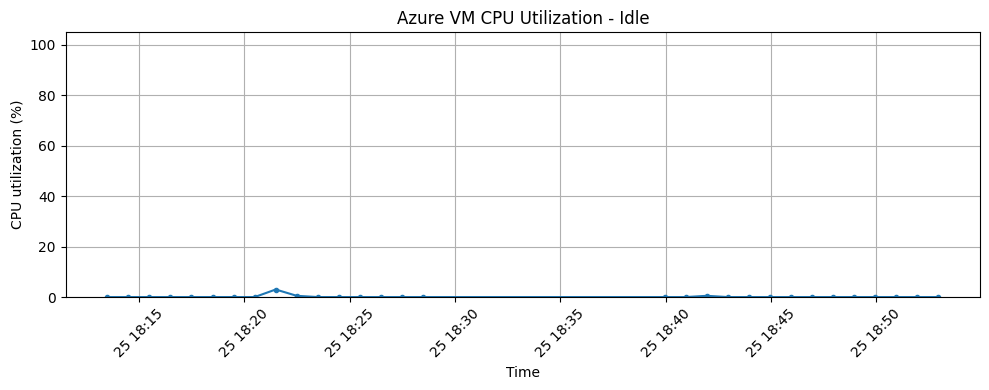

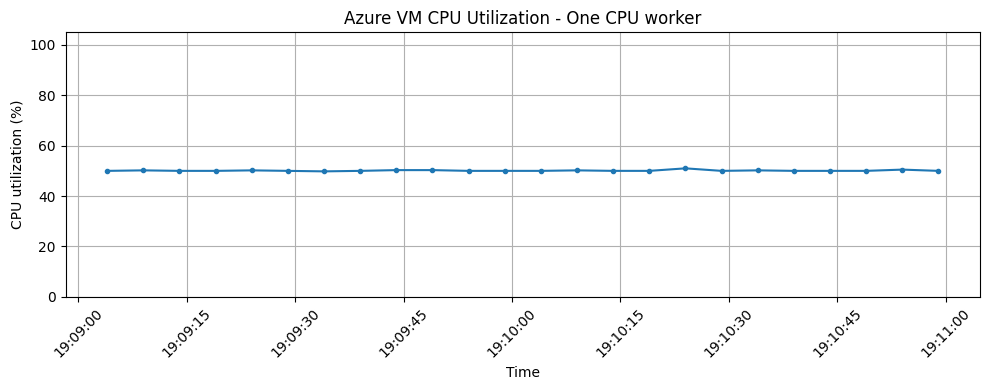

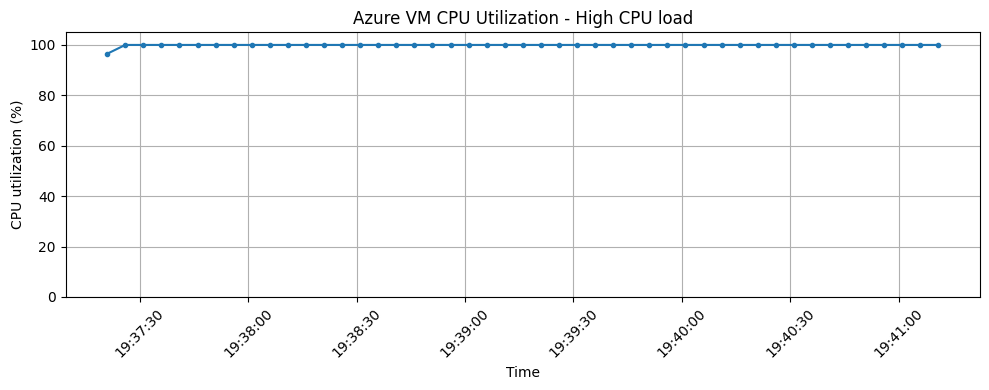

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

files = {
    "Idle": "cpu_data.csv",
    "One CPU worker": "cpu_workload.csv",
    "High CPU load": "medium_cpu_data.csv"
}

for label, filename in files.items():
    df = pd.read_csv(filename)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    plt.figure(figsize=(10, 4))
    plt.plot(
        df["timestamp"],
        df["cpu_utilization_percent"],
        marker="o",
        markersize=3
    )
    plt.title(f"Azure VM CPU Utilization - {label}")
    plt.xlabel("Time")
    plt.ylabel("CPU utilization (%)")
    plt.ylim(0, 105)
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [ ]:

import pandas as pd

# Load the three real datasets
idle = pd.read_csv("cpu_data.csv")
one_worker = pd.read_csv("cpu_workload.csv")
high_load = pd.read_csv("medium_cpu_data.csv")

# Give each dataset a clear workload label
idle["workload"] = "idle"
one_worker["workload"] = "one_worker"
high_load["workload"] = "high_load"

# Combine the datasets
data = pd.concat(
    [idle, one_worker, high_load],
    ignore_index=True
)

# Convert timestamps and sort the data
data["timestamp"] = pd.to_datetime(data["timestamp"])
data = data.sort_values("timestamp").reset_index(drop=True)

print("Total readings:", len(data))
print("\nReadings by workload:")
print(data.groupby("workload")["cpu_utilization_percent"].agg(
    ["count", "mean", "min", "max"]
))

data.head()


Total readings: 101

Readings by workload:
            count       mean   min    max
workload                                 
high_load      47  99.925532  96.5  100.0
idle           30   0.133333   0.0    3.0
one_worker     24  50.112500  49.8   51.0


,timestamp,cpu_utilization_percent,workload
0,2026-10-25 18:13:29,0.0,idle
1,2026-10-25 18:14:29,0.0,idle
2,2026-10-25 18:15:29,0.0,idle
3,2026-10-25 18:16:29,0.0,idle
4,2026-10-25 18:17:29,0.0,idle


In [ ]:

import pandas as pd

# Load the three datasets separately
idle = pd.read_csv("cpu_data.csv")
one_worker = pd.read_csv("cpu_workload.csv")
high_load = pd.read_csv("medium_cpu_data.csv")

# Store the separate sessions
sessions = {
    "idle": idle,
    "one_worker": one_worker,
    "high_load": high_load
}

prepared_data = []

for workload, df in sessions.items():
    df = df.copy()

    # Ensure readings are in time order
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp").reset_index(drop=True)

    cpu = df["cpu_utilization_percent"]

    # Previous 3 readings become input features
    df["cpu_previous_1"] = cpu.shift(1)
    df["cpu_previous_2"] = cpu.shift(2)
    df["cpu_previous_3"] = cpu.shift(3)

    # The value we want the model to predict
    df["target_cpu"] = cpu

    df["workload"] = workload

    # First 3 rows have no 3 previous readings
    df = df.dropna().copy()

    prepared_data.append(df)

ml_data = pd.concat(prepared_data, ignore_index=True)

print("Total usable prediction rows:", len(ml_data))
print("\nFirst 5 rows:")
print(ml_data[
    ["workload", "cpu_previous_3", "cpu_previous_2",
     "cpu_previous_1", "target_cpu"]
].head())

print("\nRows per workload:")
print(ml_data.groupby("workload").size())


Total usable prediction rows: 92

First 5 rows:
  workload  cpu_previous_3  cpu_previous_2  cpu_previous_1  target_cpu
0     idle             0.0             0.0             0.0         0.0
1     idle             0.0             0.0             0.0         0.0
2     idle             0.0             0.0             0.0         0.0
3     idle             0.0             0.0             0.0         0.0
4     idle             0.0             0.0             0.0         0.0

Rows per workload:
workload
high_load     44
idle          27
one_worker    21
dtype: int64


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Input features: previous CPU readings
features = [
    "cpu_previous_1",
    "cpu_previous_2",
    "cpu_previous_3"
]

X = ml_data[features]
y = ml_data["target_cpu"]

# Split each workload session in chronological order:
# first 80% for training, last 20% for testing
train_indices = []
test_indices = []

for workload, group in ml_data.groupby("workload", sort=False):
    indices = group.sort_values("timestamp").index.tolist()
    split_point = int(len(indices) * 0.8)

    train_indices.extend(indices[:split_point])
    test_indices.extend(indices[split_point:])

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]
y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

# Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predict CPU utilization on test data
predictions = model.predict(X_test)

# Evaluate predictions
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Model: Linear Regression")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print(f"MAE: {mae:.3f} percentage points")
print(f"RMSE: {rmse:.3f} percentage points")

# Compare actual and predicted CPU readings
comparison = X_test.copy()
comparison["Actual CPU (%)"] = y_test
comparison["Predicted CPU (%)"] = predictions

print("\nActual vs predicted:")
print(comparison.head(10).round(2))


Model: Linear Regression
Training rows: 72
Testing rows: 20
MAE: 0.069 percentage points
RMSE: 0.143 percentage points

Actual vs predicted:
    cpu_previous_1  cpu_previous_2  cpu_previous_3  Actual CPU (%)  \
21             0.0             0.0             0.0             0.0   
22             0.0             0.0             0.0             0.0   
23             0.0             0.0             0.0             0.0   
24             0.0             0.0             0.0             0.0   
25             0.0             0.0             0.0             0.0   
26             0.0             0.0             0.0             0.0   
43            50.2            50.0            51.0            50.0   
44            50.0            50.2            50.0            50.0   
45            50.0            50.0            50.2            50.0   
46            50.0            50.0            50.0            50.5   

    Predicted CPU (%)  
21               0.00  
22               0.00  
23              

In [ ]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create and train the model
tree_model = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Predict CPU utilization
tree_predictions = tree_model.predict(X_test)

# Evaluate performance
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))

print("Model: Decision Tree Regressor")
print("MAE:", round(tree_mae, 3), "percentage points")
print("RMSE:", round(tree_rmse, 3), "percentage points")

# Show actual versus predicted readings
tree_comparison = X_test.copy()
tree_comparison["Actual CPU (%)"] = y_test
tree_comparison["Predicted CPU (%)"] = tree_predictions

print("\nActual vs predicted:")
print(tree_comparison.head(10).round(2))


Model: Decision Tree Regressor
MAE: 0.112 percentage points
RMSE: 0.159 percentage points

Actual vs predicted:
    cpu_previous_1  cpu_previous_2  cpu_previous_3  Actual CPU (%)  \
21             0.0             0.0             0.0             0.0   
22             0.0             0.0             0.0             0.0   
23             0.0             0.0             0.0             0.0   
24             0.0             0.0             0.0             0.0   
25             0.0             0.0             0.0             0.0   
26             0.0             0.0             0.0             0.0   
43            50.2            50.0            51.0            50.0   
44            50.0            50.2            50.0            50.0   
45            50.0            50.0            50.2            50.0   
46            50.0            50.0            50.0            50.5   

    Predicted CPU (%)  
21               0.22  
22               0.22  
23               0.22  
24               0.22

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict CPU utilization
rf_predictions = rf_model.predict(X_test)

# Evaluate predictions
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("Model: Random Forest Regressor")
print("MAE:", round(rf_mae, 3), "percentage points")
print("RMSE:", round(rf_rmse, 3), "percentage points")

# Display actual and predicted readings
rf_comparison = X_test.copy()
rf_comparison["Actual CPU (%)"] = y_test
rf_comparison["Predicted CPU (%)"] = rf_predictions

print("\nActual vs predicted:")
print(rf_comparison.head(10).round(2))


Model: Random Forest Regressor
MAE: 0.125 percentage points
RMSE: 0.185 percentage points

Actual vs predicted:
    cpu_previous_1  cpu_previous_2  cpu_previous_3  Actual CPU (%)  \
21             0.0             0.0             0.0             0.0   
22             0.0             0.0             0.0             0.0   
23             0.0             0.0             0.0             0.0   
24             0.0             0.0             0.0             0.0   
25             0.0             0.0             0.0             0.0   
26             0.0             0.0             0.0             0.0   
43            50.2            50.0            51.0            50.0   
44            50.0            50.2            50.0            50.0   
45            50.0            50.0            50.2            50.0   
46            50.0            50.0            50.0            50.5   

    Predicted CPU (%)  
21               0.23  
22               0.23  
23               0.23  
24               0.23

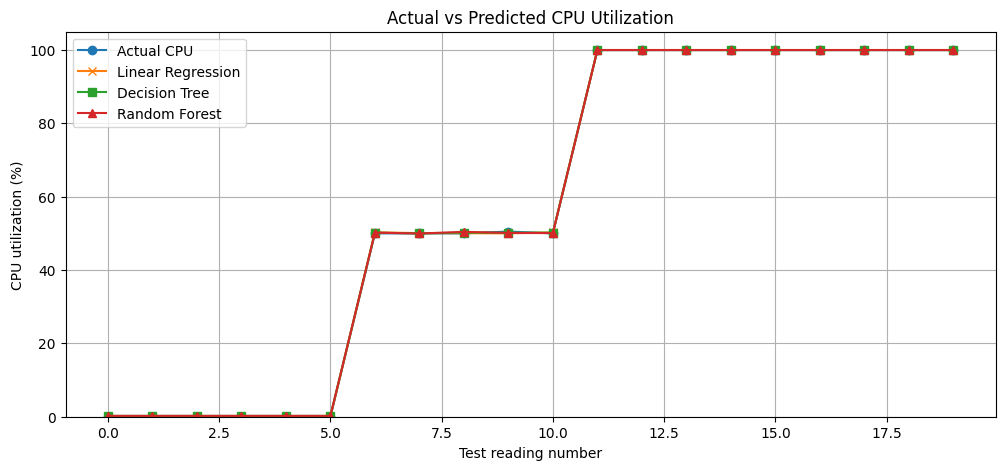

In [ ]:

import matplotlib.pyplot as plt

# Compare predictions for the same test readings
plt.figure(figsize=(12, 5))

plt.plot(
    range(len(y_test)),
    y_test.to_numpy(),
    marker="o",
    label="Actual CPU"
)

plt.plot(
    range(len(predictions)),
    predictions,
    marker="x",
    label="Linear Regression"
)

plt.plot(
    range(len(tree_predictions)),
    tree_predictions,
    marker="s",
    label="Decision Tree"
)

plt.plot(
    range(len(rf_predictions)),
    rf_predictions,
    marker="^",
    label="Random Forest"
)

plt.xlabel("Test reading number")
plt.ylabel("CPU utilization (%)")
plt.title("Actual vs Predicted CPU Utilization")
plt.ylim(0, 105)
plt.legend()
plt.grid(True)
plt.show()
